# Imports

In [1]:
# stop - UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
import os
os.environ["OMP_NUM_THREADS"] = "1"


from utils import *



import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN

from scipy.stats import gaussian_kde

# from scipy.stats import norm

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Setup

In [5]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'

# structural zones for iteration
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# type of grouping
group_type = 'dbscan'

# output path for interpretation
output_dir = r'../results'


timeline = [210, 450]
bar_width=0.4
gap=0.3


##### read into df...
df = pd.read_csv(clean_path)

# mask for garnet/cordierite lithologies (optional)...
# mask = (df['zone'] == 'MDHSZ') | (df['zone'] == 'GS') | (df['zone'] == 'CBSZ') | (df['zone'] == 'CMZI') & (df['garnet'] == 1)
mask = (df['zone'] == 'MDHSZ') | (df['zone'] == 'GS') | (df['zone'] == 'CBSZ') | (df['zone'] == 'CMZI') & (df['cordierite'] == 1)
df = df[mask]

df.sort_values('error', inplace=True)
df.reset_index(inplace=True)


df.head()

,level_0,index,sample,zone,mnz,texture,texture_chem,n,age,error,...,Er2O3,Tm2O3,Yb2O3,SO3,PbO,percent,lree,HREE,garnet,cordierite
0,2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.784962,...,0.014718,0.009812,0.009812,0.020605,0.079477,0.220495,61.972776,1.588568,1,0
1,1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.789124,...,0.009937,0.019969,0.009937,0.018184,0.132687,0.256926,57.520514,0.670830,1,0
2,3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.346540,...,0.009748,0.009748,0.009748,0.016339,0.082968,0.450800,61.526147,1.376610,1,0
3,4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.408622,...,0.009641,0.060215,0.009641,0.014777,0.085454,0.398772,60.699177,1.389823,1,1
4,6,145,P14-005A-5B,CBSZ,m11,core,Y depleted core,NaN,360.00,1.446959,...,0.009646,0.009646,0.009646,0.012540,0.080065,0.401933,61.707991,1.223163,1,0


# DBSCAN

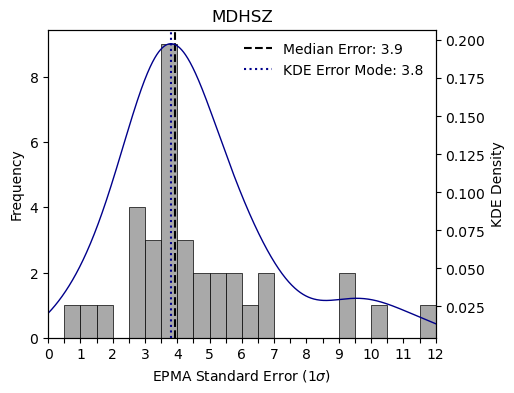

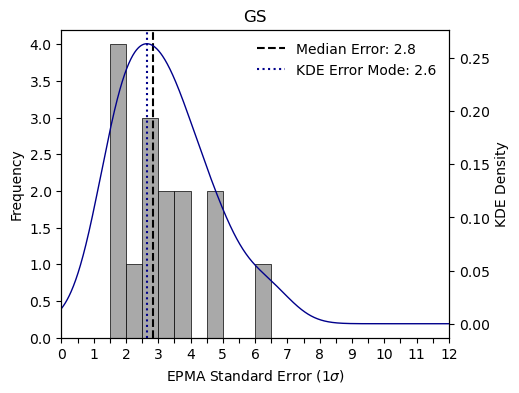

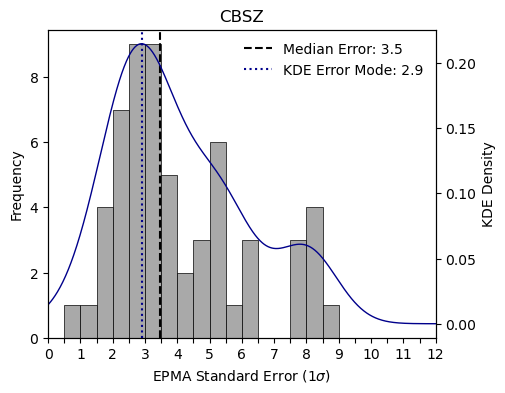

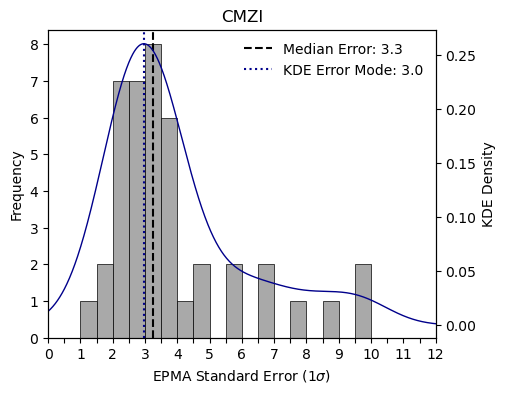

In [6]:
############################################################
# Plot Analytical Error Distributions & Get DBSCAN Epsilon
############################################################

# initialize dictionary to hold values
eps_medians = {}
eps_modes = {}

# standardized histogram bins for comparison
bins = np.arange(0, df['error'].max()+0.5, 0.5)

# x-axis array for smooth KDE plot
x = np.linspace(bins.min(), bins.max(), 1000)


##### plot errors & extract epsilon values...
# iterate through each structural zone...
for zone in structural_zones:

    ##### set up variables...
    data = df.loc[df['zone'] == zone, 'error']     # errors for current zone
    q50 = data.quantile(0.5)                       # median error
    kde = gaussian_kde(data)(x)                    # calculate KDE densities
    kde_mode_idx = np.argmax(kde)                         # get index of maximum KDE value (mode)
    kde_mode = x[kde_mode_idx]
    eps_medians[zone] = q50                         # append median to dictionary (for later use)
    eps_modes[zone] = kde_mode                    # append KDE mode value to dictionary (for later use)


    ##### plot error histogram & KDE...
    fig, ax = plt.subplots(figsize=(5,4))
    ax2 = ax.twinx()


    ax.hist(x=data, linewidth=0.5, edgecolor='k', facecolor='darkgrey', bins=bins, align='mid')
    ax2.plot(x, kde, linewidth=1, color='darkblue')
    ax.axvline(x=q50, color='k', linestyle='--', linewidth=1.5, label=f"Median Error: {round(q50, 1)}")
    ax.axvline(x=kde_mode, color='darkblue', linestyle=':', linewidth=1.5, label=f"KDE Error Mode: {round(kde_mode, 1)}")
    

    ax.legend(frameon=False)
    ax.set_xlim(bins.min(), bins.max())
    ax.set_xticks(bins)
    ax.set_xticklabels([int(i) if i%1==0 else '' for i in bins])
    ax.set_title(f"{zone}")
    ax.set_ylabel(r'Frequency')
    ax2.set_ylabel('KDE Density')
    ax.set_xlabel(r'EPMA Standard Error (1$\sigma$)')

    output_path = f"{output_dir}/{group_type}_{zone}_se_CRD"
    plt.savefig(output_path + '.png', dpi=300, bbox_inches='tight', pad_inches=0)
    plt.savefig(output_path + '.svg', dpi=300, bbox_inches='tight', pad_inches=0)

    plt.show()


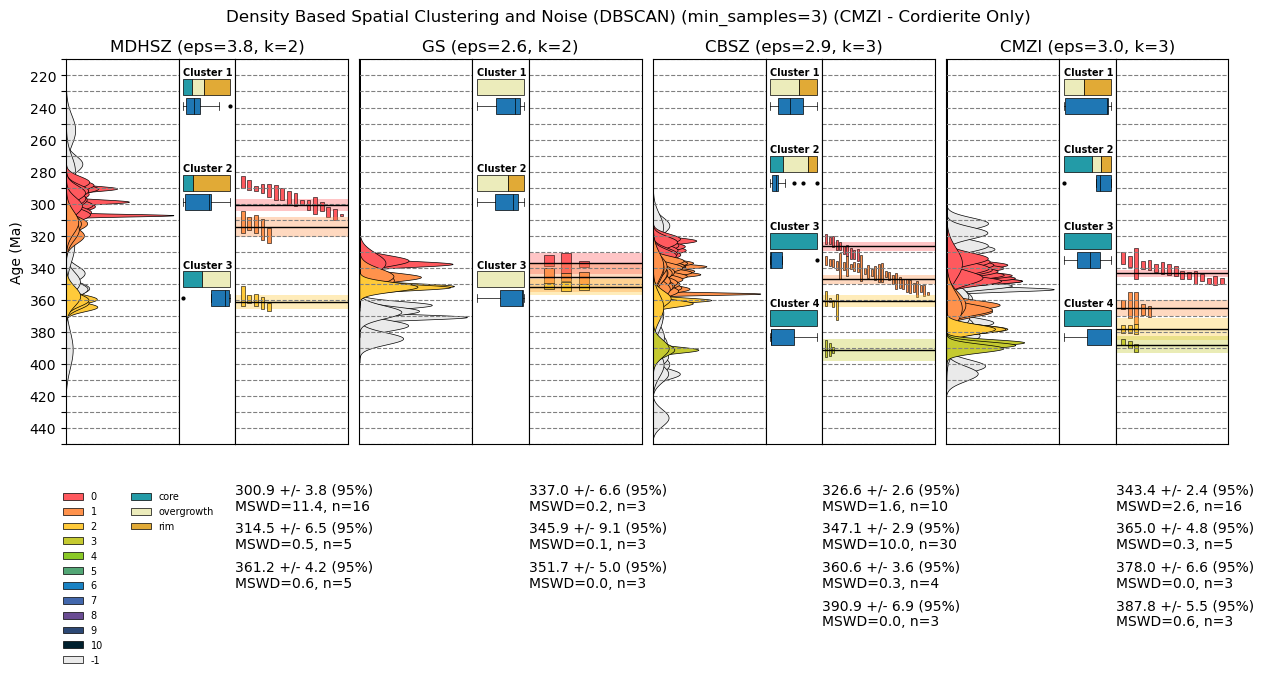

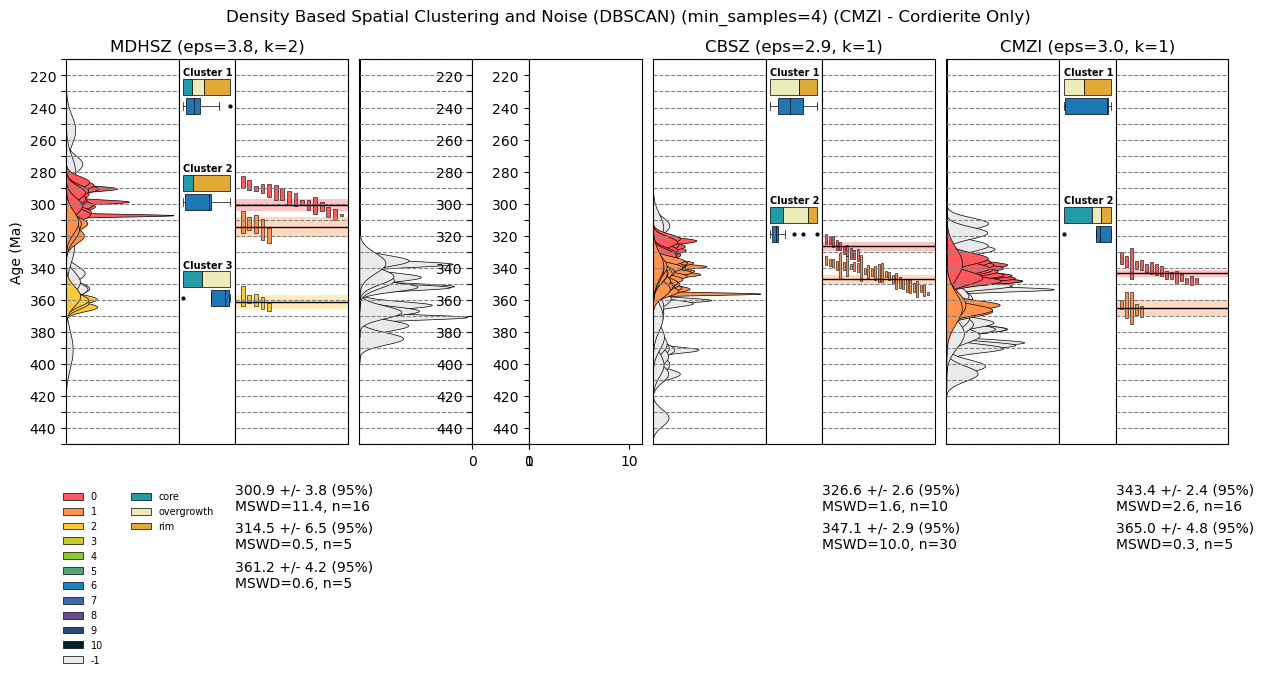

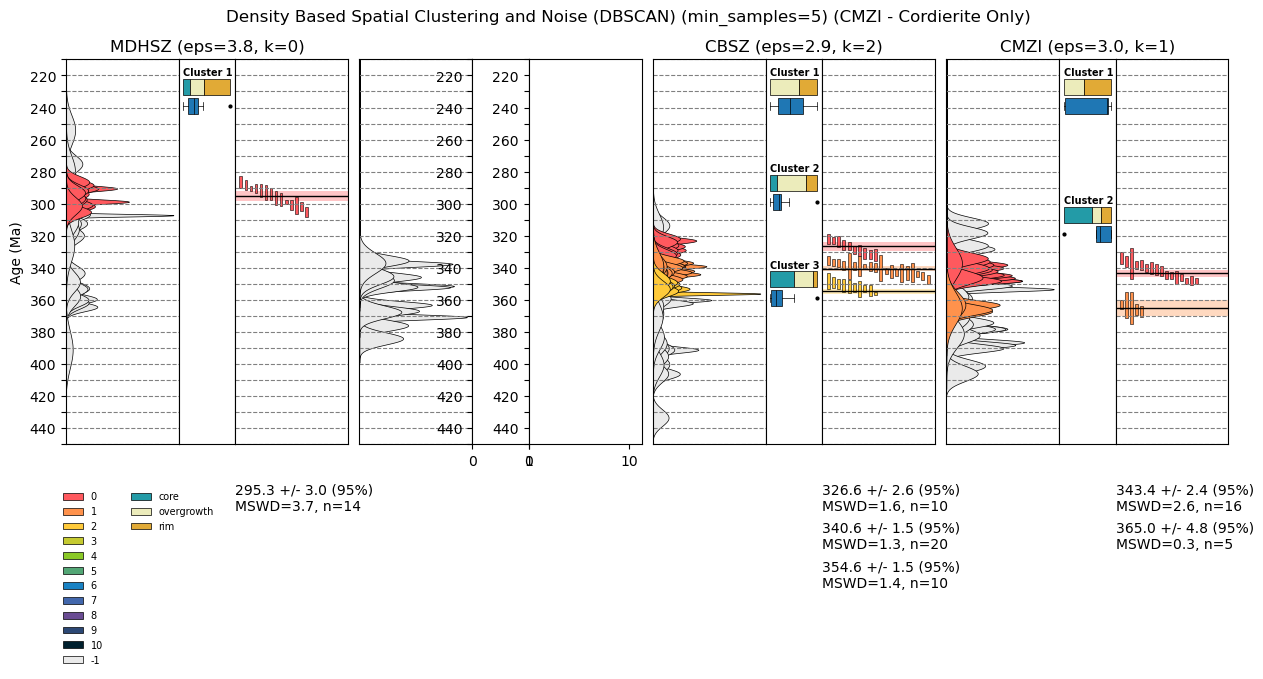

In [7]:


min_samples = [3, 4, 5]


for ms in min_samples:
    # for e in eps_values:


    fig = plt.figure(figsize=(15, 5))
    width_ratios = [1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0, 0.1, 1.0, 0.5, 1.0]
    gs = GridSpec(nrows=1, ncols=15, figure=fig, wspace=0, width_ratios=width_ratios)


    axA_1 = fig.add_subplot(gs[0, 0])
    axA_2 = fig.add_subplot(gs[0, 1], sharey=axA_1)
    axA_3 = fig.add_subplot(gs[0, 2], sharey=axA_1)
    ax_sp1 = fig.add_subplot(gs[0, 3])                 # spacer
    axB_1 = fig.add_subplot(gs[0, 4], sharey=axA_1)
    axB_2 = fig.add_subplot(gs[0, 5], sharey=axA_1)
    axB_3 = fig.add_subplot(gs[0, 6], sharey=axA_1)
    ax_sp2 = fig.add_subplot(gs[0, 7])                 # spacer
    axC_1 = fig.add_subplot(gs[0, 8], sharey=axA_1)
    axC_2 = fig.add_subplot(gs[0, 9], sharey=axA_1)
    axC_3 = fig.add_subplot(gs[0, 10], sharey=axA_1)
    ax_sp3 = fig.add_subplot(gs[0, 11])                 # spacer
    axD_1 = fig.add_subplot(gs[0, 12], sharey=axA_1)
    axD_2 = fig.add_subplot(gs[0, 13], sharey=axA_1)
    axD_3 = fig.add_subplot(gs[0, 14], sharey=axA_1)


    ax_sp1.axis("off")
    ax_sp2.axis("off")
    ax_sp3.axis("off")


    axA_1.set_ylim(450, 210)


    panel1_max = [0.0, 0.0, 0.0, 0.0]
    panel3_max = [0.0, 0.0, 0.0, 0.0]


    # iterate through structural zones...
    for idx, zone in enumerate(structural_zones):

        ##### PRE-PROCESSING
        # extract samples relevant to structural zone
        df_subset = df.loc[df['zone']==zone].copy()

        # run DBSCAN on subset with given eps & min_samples; sorted by labels 0:N then -1     
        # df_dbscan = dbscan_processing(df_subset, eps_medians[zone], ms)
        df_dbscan = dbscan_processing(df_subset, eps_modes[zone], ms)


        # separate into clusters and noise
        noise_mask = df_dbscan['labels'] == -1
        df_noise = df_dbscan.loc[noise_mask].copy()
        df_clusters = df_dbscan.loc[~noise_mask].copy()


        # get unique values of clusters (including noise -1)
        component_labels = df_clusters['labels'].unique()


        # get number of real clusters (not including noise -1)
        num_components = len(component_labels)

        
        
        # plot noise ONCE, before clusters (so it sits behind)...
        # MDHSZ
        if idx == 0 and not df_noise.empty:
            sample_max = plot_samples_panel(df_noise, axA_1, 'labels', age_group_colors, label_bool=True)
        # GS
        if idx == 1 and not df_noise.empty:
            sample_max = plot_samples_panel(df_noise, axB_1, 'labels', age_group_colors, label_bool=False)
        # CBSZ
        if idx == 2 and not df_noise.empty:
            sample_max = plot_samples_panel(df_noise, axC_1, 'labels', age_group_colors, label_bool=False)
        # CMZI
        if idx == 3 and not df_noise.empty:
            sample_max = plot_samples_panel(df_noise, axD_1, 'labels', age_group_colors, label_bool=False)

        panel1_max[idx] = max(panel1_max[idx], sample_max)



        # iterate through each cluster label (including noise -1)...
        for k, component in enumerate(component_labels):


            df_dbscan_subset = df_clusters.loc[df_clusters['labels'] == component].copy()


            spacing = (450-210) / (num_components + 1)
            center = 220 + (k * spacing)

            # df_dbscan_subset = df_dbscan_subset.loc[df_dbscan_subset['labels']!=-1]

            # MDHSZ...
            if idx==0:
                sample_max = plot_samples_panel(df_dbscan_subset, axA_1, 'labels', age_group_colors, label_bool=True)


                plot_ageinterp_panel(df_dbscan_subset, axA_3, k, age_group_colors, ci='95%')

                texture_counts = df_dbscan_subset['texture'].value_counts().to_dict()
                texture_counts = dict(sorted(texture_counts.items()))
                horizontal_stack(axA_2, k, center, texture_counts, texture_colors, df_dbscan_subset['Y2O3'].to_numpy())
                
                # axA_2.set_title(f"{zone} (k={k})", loc='center')
                axA_2.set_title(f"{zone} (eps={round(eps_modes[zone],1)}, k={k})", loc='center')

                # plot age group information below plot...
                ages = df_dbscan_subset['age'].to_numpy()
                errors = df_dbscan_subset['error'].to_numpy()
                stats = cluster_stats(ages, errors, ci='95%')
                label = ''
                if stats['n'] >= 3:
                    # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                    label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
                axA_3.text(0, -0.1-(k/10), label, transform=axA_3.transAxes, fontsize=10, ha='left', va='top')


            # GS...
            if idx==1:
                sample_max = plot_samples_panel(df_dbscan_subset, axB_1, 'labels', age_group_colors, label_bool=False)

                plot_ageinterp_panel(df_dbscan_subset, axB_3, k, age_group_colors, ci='95%')

                texture_counts = df_dbscan_subset['texture'].value_counts().to_dict()
                texture_counts = dict(sorted(texture_counts.items()))
                horizontal_stack(axB_2, k, center, texture_counts, texture_colors, df_dbscan_subset['Y2O3'].to_numpy())
                
                # axB_2.set_title(f"{zone} (k={k})", loc='center')
                axB_2.set_title(f"{zone} (eps={round(eps_modes[zone],1)}, k={k})", loc='center')

                # plot age group information below plot...
                ages = df_dbscan_subset['age'].to_numpy()
                errors = df_dbscan_subset['error'].to_numpy()
                stats = cluster_stats(ages, errors, ci='95%')
                label = ''
                if stats['n'] >= 3:
                    # label = f"\n{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                    label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
                axB_3.text(0, -0.1-(k/10), label, transform=axB_3.transAxes, fontsize=10, ha='left', va='top')


            
            # CBSZ...
            if idx==2:
                sample_max = plot_samples_panel(df_dbscan_subset, axC_1, 'labels', age_group_colors, label_bool=False)

                plot_ageinterp_panel(df_dbscan_subset, axC_3, k, age_group_colors, ci='95%')

                texture_counts = df_dbscan_subset['texture'].value_counts().to_dict()
                texture_counts = dict(sorted(texture_counts.items()))
                horizontal_stack(axC_2, k, center, texture_counts, texture_colors, df_dbscan_subset['Y2O3'].to_numpy())
                
                # axC_2.set_title(f"{zone} (k={k})", loc='center')
                axC_2.set_title(f"{zone} (eps={round(eps_modes[zone],1)}, k={k})", loc='center')

                # plot age group information below plot...
                ages = df_dbscan_subset['age'].to_numpy()
                errors = df_dbscan_subset['error'].to_numpy()
                stats = cluster_stats(ages, errors, ci='95%')
                label = ''
                if stats['n'] >= 3:
                    # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                    label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
                axC_3.text(0, -0.1-(k/10), label, transform=axC_3.transAxes, fontsize=10, ha='left', va='top')



            # CMZI...
            if idx==3:
                sample_max = plot_samples_panel(df_dbscan_subset, axD_1, 'labels', age_group_colors, label_bool=False)

                plot_ageinterp_panel(df_dbscan_subset, axD_3, k, age_group_colors, ci='95%')

                texture_counts = df_dbscan_subset['texture'].value_counts().to_dict()
                texture_counts = dict(sorted(texture_counts.items()))
                horizontal_stack(axD_2, k, center, texture_counts, texture_colors, df_dbscan_subset['Y2O3'].to_numpy())
                
                # axD_2.set_title(f"{zone} (k={k})", loc='center')
                axD_2.set_title(f"{zone} (eps={round(eps_modes[zone],1)}, k={k})", loc='center')

                # plot age group information below plot...
                ages = df_dbscan_subset['age'].to_numpy()
                errors = df_dbscan_subset['error'].to_numpy()
                stats = cluster_stats(ages, errors, ci='95%')
                label = ''
                if stats['n'] >= 3:
                    # label = f"\n{round(stats['mean'],1)} +/- {round(stats['halfwidth'],1)} (2 sig.)\nMSWD={round(stats['mswd'], 1)}\n"
                    label += f"{round(stats['mean'], 1)} +/- {round(stats['halfwidth'], 1)} (95%)\nMSWD={round(stats['mswd'], 1)}, n={stats['n']}"
                axD_3.text(0, -0.1-(k/10), label, transform=axD_3.transAxes, fontsize=10, ha='left', va='top')



            panel1_max[idx] = max(panel1_max[idx], sample_max)
        panel3_max[idx] = df_dbscan.value_counts('labels').max()




    # hard-pin the inverted y on all shared siblings
    for a in axA_1.get_shared_y_axes().get_siblings(axA_1):
        a.set_ylim(450, 210)
        a.set_autoscale_on(False)

    # also pin the memoized twins so they cannot drift
    for mid in (axA_2, axB_2, axC_2, axD_2):
        if hasattr(mid, "_box_twin"):
            mid._box_twin.set_ylim(450, 210)
            mid._box_twin.set_autoscale_on(False)



    axA_1.set_xlim(0, panel1_max[0] * 1.05)
    axA_3.set_xlim(0, panel3_max[0] * (bar_width + gap + 0.05))

    axB_1.set_xlim(0, panel1_max[1] * 1.05)
    axB_3.set_xlim(0, panel3_max[1] * (bar_width + gap + 0.05))

    axC_1.set_xlim(0, panel1_max[2] * 1.05)
    axC_3.set_xlim(0, panel3_max[2] * (bar_width + gap + 0.05))

    axD_1.set_xlim(0, panel1_max[3] * 1.05)
    axD_3.set_xlim(0, panel3_max[3] * (bar_width + gap + 0.05))



    # create legend...

    patches = []
    for k,v in age_group_colors.items():
        patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))

    # create legend for texture
    axA_1.legend(patches, [l.get_label() for l in patches], loc='upper left', bbox_to_anchor=(-0.1,-0.1), frameon=False, fontsize=7)


    # patches for texture...
    patches = []
    for k,v in texture_colors.items():
        patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
    axA_2.legend(patches, [l.get_label() for l in patches], loc='upper left', bbox_to_anchor=(-1,-0.1), frameon=False, fontsize=7)



    plt.suptitle(f"Density Based Spatial Clustering and Noise (DBSCAN) (min_samples={ms}) (CMZI - Cordierite Only)")
    output_path = f"{output_dir}/{group_type}_{ms}_interpretation_CRD"
    plt.savefig(output_path + '.png', dpi=300, bbox_inches='tight', pad_inches=0)
    plt.savefig(output_path + '.svg', dpi=300, bbox_inches='tight', pad_inches=0)

    plt.show()

